In [32]:
import pandas as pd
import sqlite3
import matplotlib.pyplot as plt
import plotly as px

In [33]:
df= pd.read_csv('StudentsPerformance.csv', delimiter=',')

In [34]:
df.head(10)

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75
5,female,group B,associate's degree,standard,none,71,83,78
6,female,group B,some college,standard,completed,88,95,92
7,male,group B,some college,free/reduced,none,40,43,39
8,male,group D,high school,free/reduced,completed,64,64,67
9,female,group B,high school,free/reduced,none,38,60,50


In [35]:
df.isnull().sum()

,0
gender,0
race/ethnicity,0
parental level of education,0
lunch,0
test preparation course,0
math score,0
reading score,0
writing score,0


In [36]:
df['gender'].unique()

array(['female', 'male'], dtype=object)

In [37]:
# Mapeando 'female' para 0 e 'male' para 1
df['gender'] = df['gender'].map({'female': 0, 'male': 1})

In [38]:
df['race/ethnicity'].unique()

array(['group B', 'group C', 'group A', 'group D', 'group E'],
      dtype=object)

In [39]:
df['race/ethnicity'] = df['race/ethnicity'].map({'group A': 0, 'group B': 1, 'group C': 2, 'group D': 3, 'group E': 4})

In [40]:
df['parental level of education'].unique()

array(["bachelor's degree", 'some college', "master's degree",
       "associate's degree", 'high school', 'some high school'],
      dtype=object)

In [41]:
df = df.rename(columns={'parental level of education': 'parental_education'})

In [42]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
df['parental_education'] = le.fit_transform(df['parental_education'])

In [43]:
df['lunch'].unique()

array(['standard', 'free/reduced'], dtype=object)

In [44]:
le = LabelEncoder()
df['lunch'] = le.fit_transform(df['lunch'])

In [45]:
df['test preparation course'].unique()

array(['none', 'completed'], dtype=object)

In [46]:
df = df.rename(columns={'test preparation course': 'preparation_test'})

In [47]:
df['preparation_test'] = df['preparation_test'].map({'none': 0, 'completed': 1})

In [48]:
df.head(10)

,gender,race/ethnicity,parental_education,lunch,preparation_test,math score,reading score,writing score
0,0,1,1,1,0,72,72,74
1,0,2,4,1,1,69,90,88
2,0,1,3,1,0,90,95,93
3,1,0,0,0,0,47,57,44
4,1,2,4,1,0,76,78,75
5,0,1,0,1,0,71,83,78
6,0,1,4,1,1,88,95,92
7,1,1,4,0,0,40,43,39
8,1,3,2,0,1,64,64,67
9,0,1,2,0,0,38,60,50


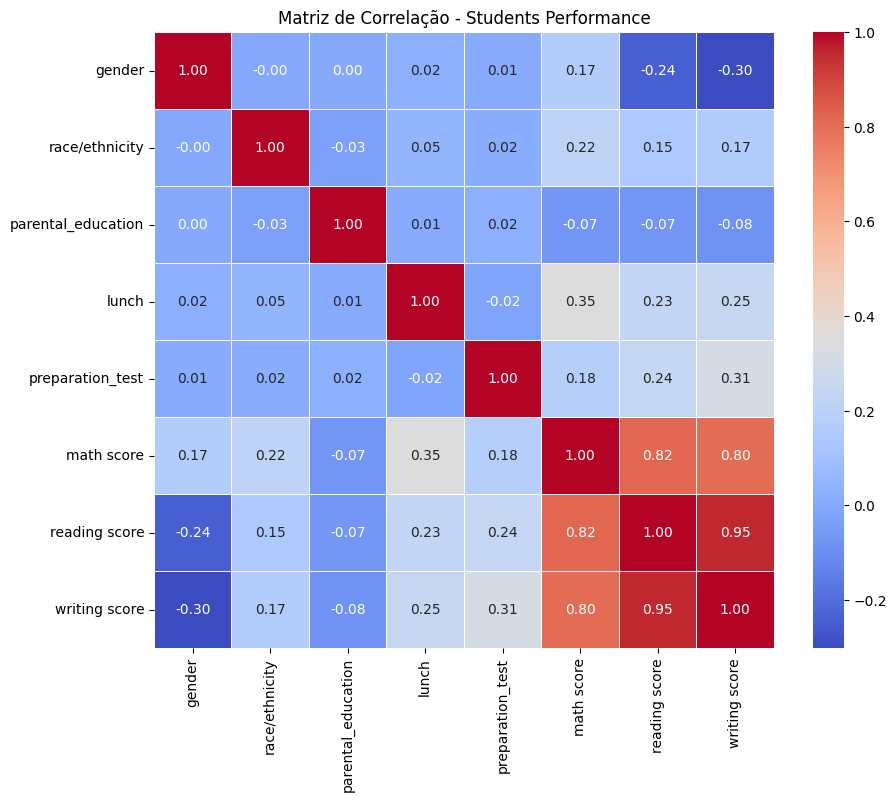

In [49]:
import seaborn as sns

# 1. Calcular a matriz de correlação
corr = df.corr()

# 2. Plotar o Heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Matriz de Correlação - Students Performance')
plt.show()

###**Qual é a média de desempenho geral dos alunos nas três disciplinas (matemática, leitura e escrita) e em qual delas os estudantes apresentam maior dificuldade?**

Médias de desempenho:
math score       66.089
reading score    69.169
writing score    68.054
dtype: float64



/tmp/ipykernel_3691/1511455430.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=medias.index, y=medias.values, palette='viridis')


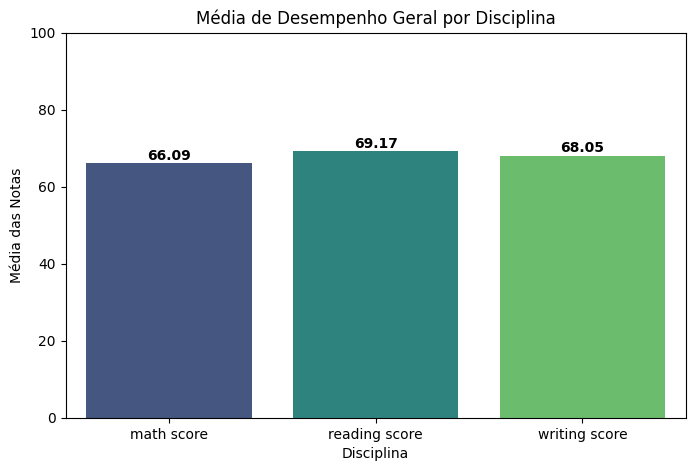

In [50]:
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Calcular a média de cada disciplina
medias = df[['math score', 'reading score', 'writing score']].mean()
print("Médias de desempenho:")
print(medias)
print()

# 2. Plotar o gráfico de barras
plt.figure(figsize=(8, 5))
sns.barplot(x=medias.index, y=medias.values, palette='viridis')

plt.title('Média de Desempenho Geral por Disciplina')
plt.xlabel('Disciplina')
plt.ylabel('Média das Notas')
plt.ylim(0, 100) # Notas vão de 0 a 100

# Adicionar os valores acima de cada barra
for i, v in enumerate(medias.values):
    plt.text(i, v + 1, f"{v:.2f}", ha='center', fontweight='bold')

plt.show()

Podemos perceber com o gráfico que a média da disciplina Matemática está um pouco abaixo das outras duas, porém todas estão abaixo de 70%.

###**O nível de escolaridade dos pais (parental level of education) influencia diretamente as notas dos alunos? Existe alguma disciplina onde esse impacto é mais evidente?**

In [55]:
import plotly.express as px
from sklearn.preprocessing import LabelEncoder

# Agrupando os dados pela escolaridade dos pais para obter as médias das notas
df_grouped = df.groupby('parental_education')[['math score', 'reading score', 'writing score']].mean().reset_index()

# Recriando o LabelEncoder especificamente para a coluna 'parental_education' original
# para mapear os índices de volta para os nomes de forma correta e automática
le_parental = LabelEncoder()
_ = le_parental.fit(["bachelor's degree", "some college", "master's degree", "associate's degree", "high school", "some high school"])
classes_escolaridade = le_parental.classes_

# Mapeando os códigos numéricos de volta para as descrições em texto
df_grouped['parental_education'] = df_grouped['parental_education'].map(lambda x: classes_escolaridade[x])

# Criando o gráfico de barras agrupado com os nomes reais das categorias
fig = px.bar(
    df_grouped,
    x="parental_education",
    y=['math score', 'reading score', 'writing score'],
    barmode='group',
    title="Média das Notas por Escolaridade Parental",
    labels={'parental_education': 'Escolaridade dos Pais', 'value': 'Nota Média', 'variable': 'Disciplina'}
)
fig.show()

Alunos cujos pais possuem maior nível de escolaridade (como Master's degree e Bachelor's degree) apresentam consistentemente as maiores médias nas três disciplinas.

O impacto da escolaridade é especialmente visível nas disciplinas de leitura (Reading) e escrita (Writing), onde as médias dos alunos com pais pós-graduados chegam a passar dos 75 pontos, enquanto os alunos cujos pais têm apenas o ensino médio (High School) ficam próximos dos 62 a 64 pontos (uma diferença de mais de 10 pontos)

###**Os alunos que concluíram o curso preparatório (test preparation course) tiveram um desempenho significativamente superior aos que não fizeram? A melhoria compensa o investimento no curso?**

In [59]:
# Agrupando os dados pela coluna de teste preparatório para obter as médias das notas
df_grouped = df.groupby('preparation_test')[['math score', 'reading score', 'writing score']].mean().reset_index()

# Mapeando os valores numéricos de volta para os nomes textuais originais
df_grouped['preparation_test'] = df_grouped['preparation_test'].map({0: 'none', 1: 'completed'})

# Criando o gráfico de barras agrupado com os nomes reais das categorias
fig = px.bar(
    df_grouped,
    x="preparation_test",
    y=['math score', 'reading score', 'writing score'],
    barmode='group',
    title="Média das Notas por Teste Preparatório",
    labels={'preparation_test': 'Curso Preparatório', 'value': 'Nota Média', 'variable': 'Disciplina'}
)
fig.show()

Podemos notar que nas 3 matérias tivemos um melhor desempenho de quem completou o teste preparatório, podendo assim afirmar sua eficiência.

###**Existe diferença expressiva de desempenho entre os alunos que recebem taxa de almoço reduzida/gratuita (lunch: free/reduced) e os que pagam a taxa padrão (standard)?**

In [64]:
# Agrupando os dados pela coluna de almoço para obter as médias das notas
df_grouped = df.groupby('lunch')[['math score', 'reading score', 'writing score']].mean().reset_index()

# Recriando o LabelEncoder especificamente para a coluna 'lunch' original
# para mapear os índices de volta para os nomes de forma correta e automática
le_lunch = LabelEncoder()
_ = le_lunch.fit(['standard', 'free/reduced'])
lunch_le = le_lunch.classes_

# Mapeando os códigos numéricos de volta para as descrições em texto
df_grouped['lunch'] = df_grouped['lunch'].map(lambda x: lunch_le[x])

# Criando o gráfico de barras agrupado com os nomes reais das categorias
fig = px.bar(
    df_grouped,
    x="lunch",
    y=['math score', 'reading score', 'writing score'],
    barmode='group',
    title="Média das Notas por Almoço",
    labels={'lunch': 'Almoço', 'value': 'Nota Média', 'variable': 'Disciplina'}
)
fig.show()

Podemos perceber no gráfico acima que as pessoas que tiveram o almoço padrão conseguem obter notas significativamente melhores do que as pessoas com almoço gratuitos/preço reduzido.

###**Qual percentual de alunos está abaixo da média mínima de aprovação (ex.: nota inferior a 60) em duas ou mais disciplinas e qual é o perfil predominante desse grupo?**

In [65]:
import numpy as np

# 1. Definir a condição de nota inferior a 60 nas três matérias
abaixo_mat = df['math score'] < 60
abaixo_lei = df['reading score'] < 60
abaixo_esc = df['writing score'] < 60

# 2. Somar em quantas disciplinas cada aluno ficou abaixo da média mínima de 60
reprovacoes = abaixo_mat.astype(int) + abaixo_lei.astype(int) + abaixo_esc.astype(int)

# 3. Filtrar alunos que falharam em duas ou mais disciplinas
alunos_em_risco = df[reprovacoes >= 2]

# 4. Calcular o percentual total
percentual_risco = (len(alunos_em_risco) / len(df)) * 100
print(f"Percentual de alunos abaixo de 60 em duas ou mais disciplinas: {percentual_risco:.2f}% ({len(alunos_em_risco)} alunos)\n")

# 5. Mapeamentos para exibição legível do perfil predominante
mapeamento_genero = {0: 'Female', 1: 'Male'}
mapeamento_etnia = {0: 'Group A', 1: 'Group B', 2: 'Group C', 3: 'Group D', 4: 'Group E'}
mapeamento_almoco = {0: 'free/reduced', 1: 'standard'}
mapeamento_preparatorio = {0: 'none', 1: 'completed'}

# Categorias de escolaridade dos pais ordenadas do LabelEncoder original
classes_escolaridade = ["associate's degree", "bachelor's degree", "high school", "master's degree", "some college", "some high school"]

# Copiar dataframe para mapeamento legível
perfil_df = alunos_em_risco.copy()
perfil_df['gender'] = perfil_df['gender'].map(mapeamento_genero)
perfil_df['race/ethnicity'] = perfil_df['race/ethnicity'].map(mapeamento_etnia)
perfil_df['lunch'] = perfil_df['lunch'].map(mapeamento_almoco)
perfil_df['preparation_test'] = perfil_df['preparation_test'].map(mapeamento_preparatorio)
perfil_df['parental_education'] = perfil_df['parental_education'].map(lambda x: classes_escolaridade[x])

# Exibir a moda de cada variável para determinar o perfil predominante
print("--- Perfil Predominante do Grupo em Risco ---")
print(f"Gênero Predominante: {perfil_df['gender'].mode()[0]} ({perfil_df['gender'].value_counts(normalize=True).iloc[0]*100:.1f}%)")
print(f"Grupo Étnico Predominante: {perfil_df['race/ethnicity'].mode()[0]} ({perfil_df['race/ethnicity'].value_counts(normalize=True).iloc[0]*100:.1f}%)")
print(f"Escolaridade dos Pais Predominante: {perfil_df['parental_education'].mode()[0]} ({perfil_df['parental_education'].value_counts(normalize=True).iloc[0]*100:.1f}%)")
print(f"Tipo de Almoço Predominante: {perfil_df['lunch'].mode()[0]} ({perfil_df['lunch'].value_counts(normalize=True).iloc[0]*100:.1f}%)")
print(f"Status do Curso Preparatório: {perfil_df['preparation_test'].mode()[0]} ({perfil_df['preparation_test'].value_counts(normalize=True).iloc[0]*100:.1f}%)")

Percentual de alunos abaixo de 60 em duas ou mais disciplinas: 27.10% (271 alunos)

--- Perfil Predominante do Grupo em Risco ---
Gênero Predominante: Male (60.5%)
Grupo Étnico Predominante: Group C (32.8%)
Escolaridade dos Pais Predominante: high school (27.7%)
Tipo de Almoço Predominante: free/reduced (52.0%)
Status do Curso Preparatório: none (79.7%)


**1. Percentual de Alunos em Risco:**
27,10% do total de alunos estão abaixo da média mínima em pelo menos duas disciplinas.

**2. Perfil Predominante Desse Grupo:**
Ao analisar as características desse grupo em risco, conseguimos desenhar o seguinte perfil majoritário:

* **Gênero:** Masculino (representa 60,5% desse grupo).

* **Grupo Étnico:** Group C (representa 32,8% do grupo).

* **Escolaridade dos Pais:** High School (Ensino Médio) (representa 27,7% do grupo).

* **Tipo de Almoço:** Free/Reduced (Almoço gratuito ou reduzido) (representa 52,0% do grupo).

* **Curso Preparatório:** Não realizaram nenhum curso preparatório (79,7% do grupo).